Cell 1 — Import Libraries


In [4]:
# ============================================================
# OPEN-ENDED LAB I
# Exploring Predictive Analysis with Regression
# Dataset: Yacht Hydrodynamics
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error, r2_score

# Set visualization style
sns.set_theme(style="whitegrid")

print("=" * 65)
print("EXPLORING PREDICTIVE ANALYSIS WITH REGRESSION")
print("Dataset: Yacht Hydrodynamics")
print("=" * 65)

EXPLORING PREDICTIVE ANALYSIS WITH REGRESSION
Dataset: Yacht Hydrodynamics


Cell 2 — Load the Excel Dataset

In [5]:
# ============================================================
# SECTION 1: LOAD THE DATASET
# ============================================================

file_path = r"C:\BSE-7A\ML Lab\Tasks\OpenEndedLab_06\yacht_hydrodynamics.xlsx"

df = pd.read_excel(file_path)

# Assign meaningful column names
df.columns = [
    "Center_of_Buoyancy",
    "Prismatic_Coefficient",
    "Length_Displacement_Ratio",
    "Beam_Draught_Ratio",
    "Length_Beam_Ratio",
    "Froude_Number",
    "Residuary_Resistance"
]

print("\nFIRST FIVE RECORDS")
print(df.head().to_string(index=False))

print("\nDATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nTOTAL OBSERVATIONS:", len(df))


FIRST FIVE RECORDS
 Center_of_Buoyancy  Prismatic_Coefficient  Length_Displacement_Ratio  Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number  Residuary_Resistance
               -2.3                  0.568                       4.78                3.99               3.17          0.125                  0.11
               -2.3                  0.568                       4.78                3.99               3.17          0.150                  0.27
               -2.3                  0.568                       4.78                3.99               3.17          0.175                  0.47
               -2.3                  0.568                       4.78                3.99               3.17          0.200                  0.78
               -2.3                  0.568                       4.78                3.99               3.17          0.225                  1.18

DATASET SHAPE
(308, 7)

COLUMN NAMES
['Center_of_Buoyancy', 'Prismatic_Coefficient', 'Length_Displaceme

Cell 3 — Understand the Dataset

In [6]:
# ============================================================
# SECTION 2: UNDERSTAND THE DATASET
# ============================================================

print("\nDATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
print(df.describe().round(3))

print("\nFIRST FIVE ROWS")
print(df.head())


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Center_of_Buoyancy         308 non-null    float64
 1   Prismatic_Coefficient      252 non-null    float64
 2   Length_Displacement_Ratio  308 non-null    float64
 3   Beam_Draught_Ratio         308 non-null    float64
 4   Length_Beam_Ratio          308 non-null    float64
 5   Froude_Number              308 non-null    float64
 6   Residuary_Resistance       308 non-null    float64
dtypes: float64(7)
memory usage: 17.0 KB

STATISTICAL SUMMARY
       Center_of_Buoyancy  Prismatic_Coefficient  Length_Displacement_Ratio  \
count             308.000                252.000                    308.000   
mean               -2.382                  0.564                      4.008   
std                 1.513                  0.023                      1.644   
min 

Cell 4 — Check Missing Values and Duplicates

In [7]:
# ============================================================
# SECTION 3: DATA QUALITY CHECKS
# ============================================================

print("\nMISSING VALUES IN EACH COLUMN")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\nTOTAL DUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nDATA TYPES")
print(df.dtypes)

# Convert columns to numeric values if necessary
df = df.apply(pd.to_numeric, errors="coerce")

# Remove rows containing missing or invalid values
df = df.dropna().reset_index(drop=True)

print("\nDATASET SHAPE AFTER CLEANING")
print(df.shape)


MISSING VALUES IN EACH COLUMN
Center_of_Buoyancy            0
Prismatic_Coefficient        56
Length_Displacement_Ratio     0
Beam_Draught_Ratio            0
Length_Beam_Ratio             0
Froude_Number                 0
Residuary_Resistance          0
dtype: int64

TOTAL MISSING VALUES
56

TOTAL DUPLICATE RECORDS
0

DATA TYPES
Center_of_Buoyancy           float64
Prismatic_Coefficient        float64
Length_Displacement_Ratio    float64
Beam_Draught_Ratio           float64
Length_Beam_Ratio            float64
Froude_Number                float64
Residuary_Resistance         float64
dtype: object

DATASET SHAPE AFTER CLEANING
(252, 7)


Cell 5 — Define Input Features and Target Variable

In [8]:
# ============================================================
# SECTION 4: DEFINE FEATURES AND TARGET
# ============================================================

feature_columns = [
    "Center_of_Buoyancy",
    "Prismatic_Coefficient",
    "Length_Displacement_Ratio",
    "Beam_Draught_Ratio",
    "Length_Beam_Ratio",
    "Froude_Number"
]

X = df[feature_columns]

y = df["Residuary_Resistance"]

print("\nINPUT FEATURES")
print(X.head())

print("\nTARGET VARIABLE: RESIDUARY RESISTANCE")
print(y.head())

print("\nNUMBER OF INPUT FEATURES:", X.shape[1])
print("NUMBER OF TARGET VALUES:", len(y))


INPUT FEATURES
   Center_of_Buoyancy  Prismatic_Coefficient  Length_Displacement_Ratio  \
0                -2.3                  0.568                       4.78   
1                -2.3                  0.568                       4.78   
2                -2.3                  0.568                       4.78   
3                -2.3                  0.568                       4.78   
4                -2.3                  0.568                       4.78   

   Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number  
0                3.99               3.17          0.125  
1                3.99               3.17          0.150  
2                3.99               3.17          0.175  
3                3.99               3.17          0.200  
4                3.99               3.17          0.225  

TARGET VARIABLE: RESIDUARY RESISTANCE
0    0.11
1    0.27
2    0.47
3    0.78
4    1.18
Name: Residuary_Resistance, dtype: float64

NUMBER OF INPUT FEATURES: 6
NUMBER OF TARGET VALUES:

Cell 6 — Analyze the Target Variable

In [9]:
# ============================================================
# SECTION 5: TARGET VARIABLE ANALYSIS
# ============================================================

print("\nRESIDUARY RESISTANCE STATISTICS")
print(y.describe().round(3))

print("\nMINIMUM RESIDUARY RESISTANCE:", round(y.min(), 3))
print("MAXIMUM RESIDUARY RESISTANCE:", round(y.max(), 3))
print("AVERAGE RESIDUARY RESISTANCE:", round(y.mean(), 3))
print("MEDIAN RESIDUARY RESISTANCE:", round(y.median(), 3))


RESIDUARY RESISTANCE STATISTICS
count    252.000
mean      10.296
std       14.941
min        0.010
25%        0.768
50%        3.010
75%       12.722
max       62.420
Name: Residuary_Resistance, dtype: float64

MINIMUM RESIDUARY RESISTANCE: 0.01
MAXIMUM RESIDUARY RESISTANCE: 62.42
AVERAGE RESIDUARY RESISTANCE: 10.296
MEDIAN RESIDUARY RESISTANCE: 3.01


Cell 7 — Visualize the Distribution of the Target

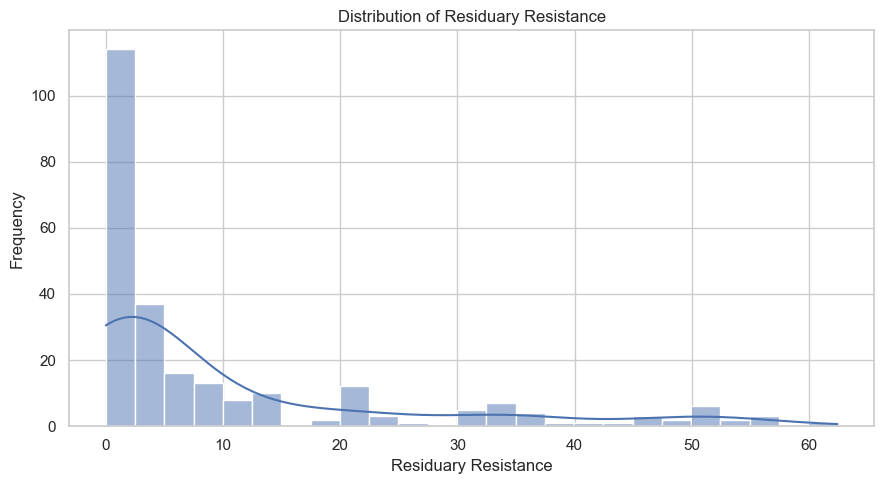

In [10]:
# ============================================================
# SECTION 6: DISTRIBUTION OF RESIDUARY RESISTANCE
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Residuary_Resistance",
    bins=25,
    kde=True
)

plt.title("Distribution of Residuary Resistance")
plt.xlabel("Residuary Resistance")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Cell 8 — Boxplot to Investigate Potential Outliers

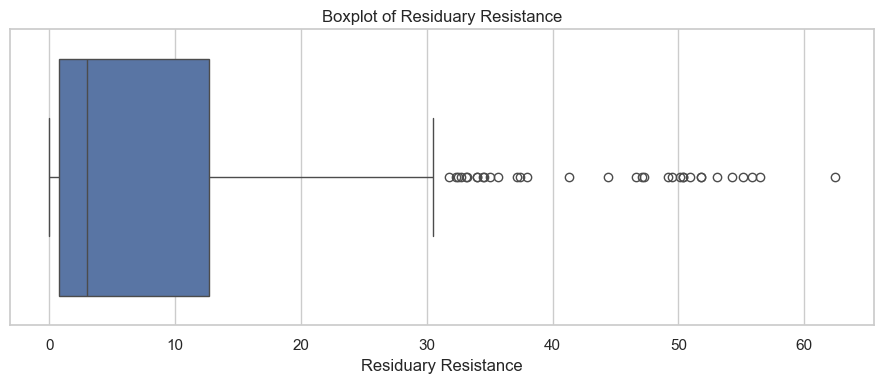

In [11]:
# ============================================================
# SECTION 7: BOXPLOT OF TARGET VARIABLE
# ============================================================

plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df["Residuary_Resistance"]
)

plt.title("Boxplot of Residuary Resistance")
plt.xlabel("Residuary Resistance")

plt.tight_layout()
plt.show()

Cell 9 — Boxplots of Input Features

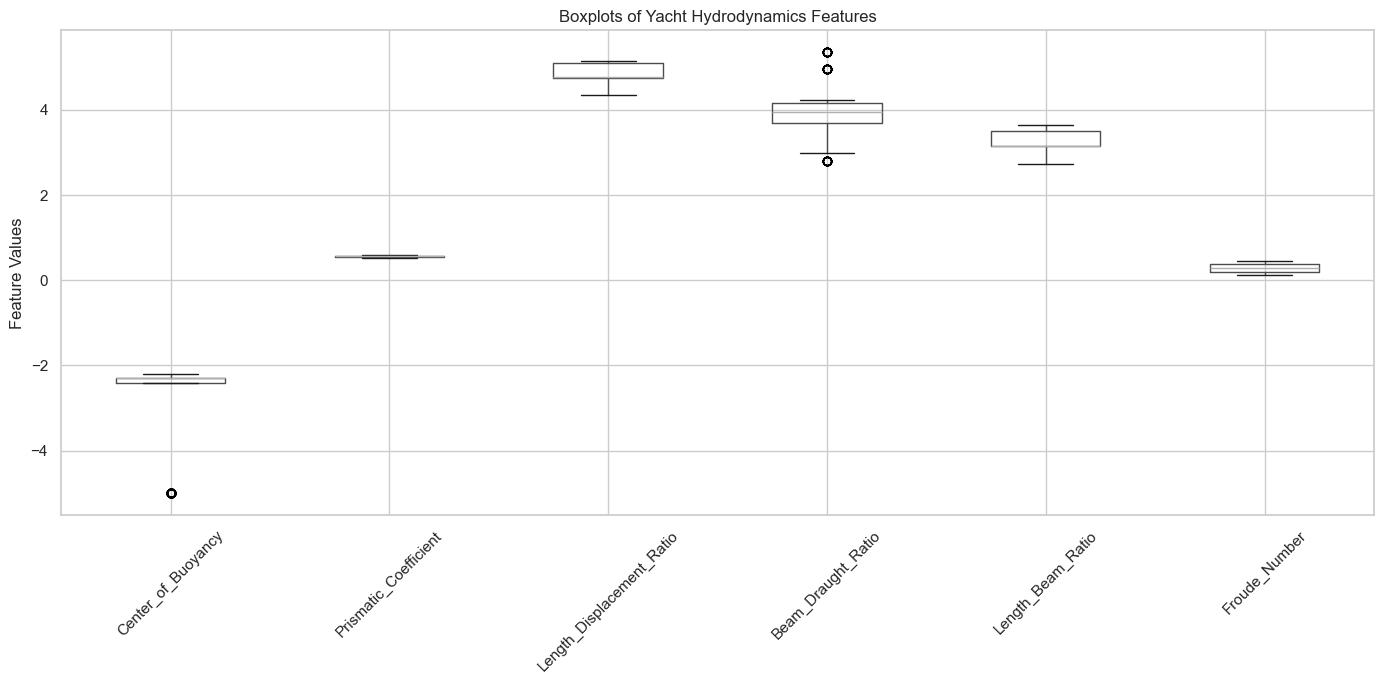

In [12]:
# ============================================================
# SECTION 8: BOXPLOTS OF INPUT FEATURES
# ============================================================

plt.figure(figsize=(14, 7))

df[feature_columns].boxplot(rot=45)

plt.title("Boxplots of Yacht Hydrodynamics Features")
plt.ylabel("Feature Values")

plt.tight_layout()
plt.show()

Cell 10 — Correlation Heatmap

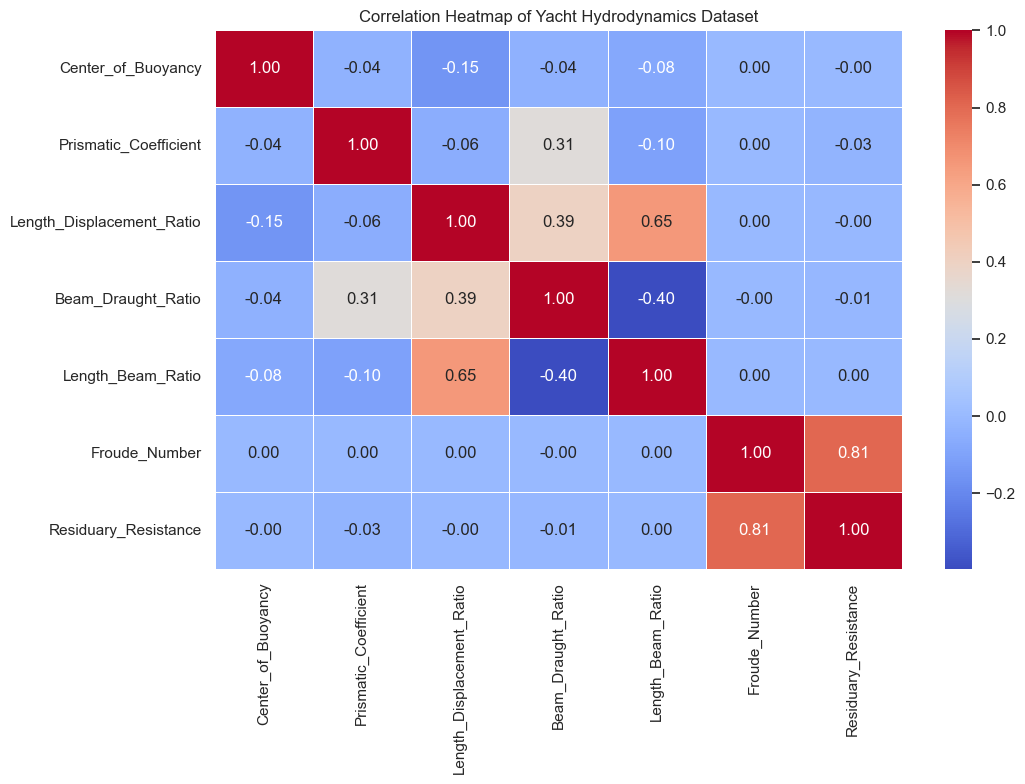

In [13]:
# ============================================================
# SECTION 9: CORRELATION HEATMAP
# ============================================================

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Yacht Hydrodynamics Dataset")

plt.tight_layout()
plt.show()

Cell 11 — Relationship Between Features and Target

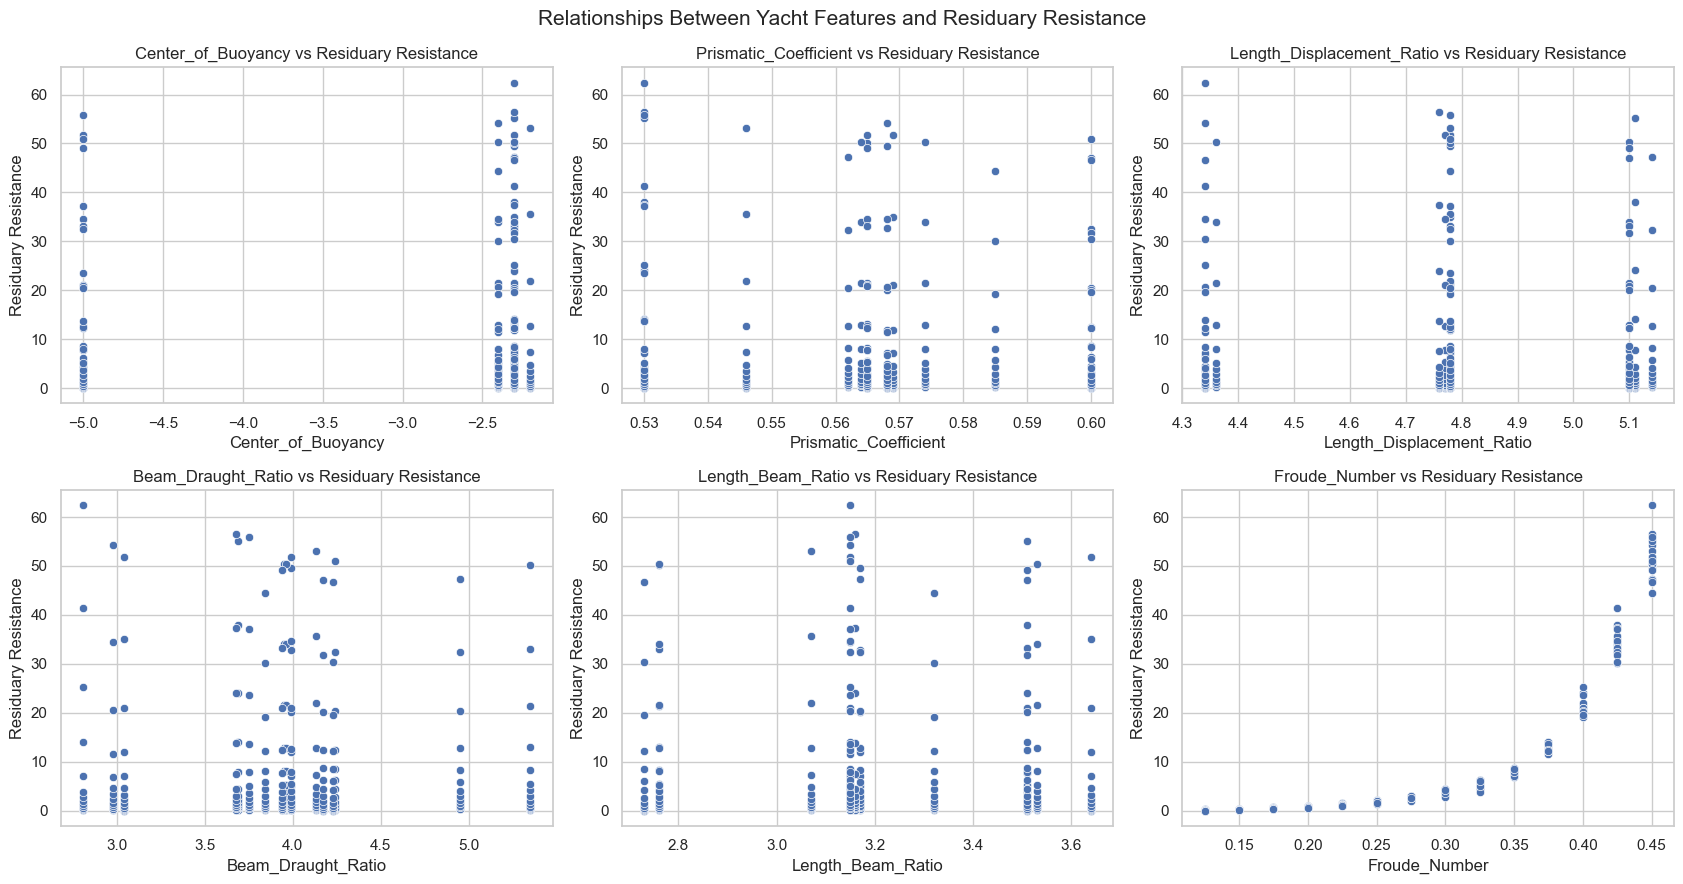

In [14]:
# ============================================================
# SECTION 10: FEATURE VS TARGET RELATIONSHIPS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for i, feature in enumerate(feature_columns):

    row = i // 3
    col = i % 3

    sns.scatterplot(
        data=df,
        x=feature,
        y="Residuary_Resistance",
        ax=axes[row, col]
    )

    axes[row, col].set_title(
        f"{feature} vs Residuary Resistance"
    )

    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel("Residuary Resistance")

plt.suptitle(
    "Relationships Between Yacht Features and Residuary Resistance",
    fontsize=15
)

plt.tight_layout()
plt.show()

Cell 12 — Visualize the Nonlinear Relationship


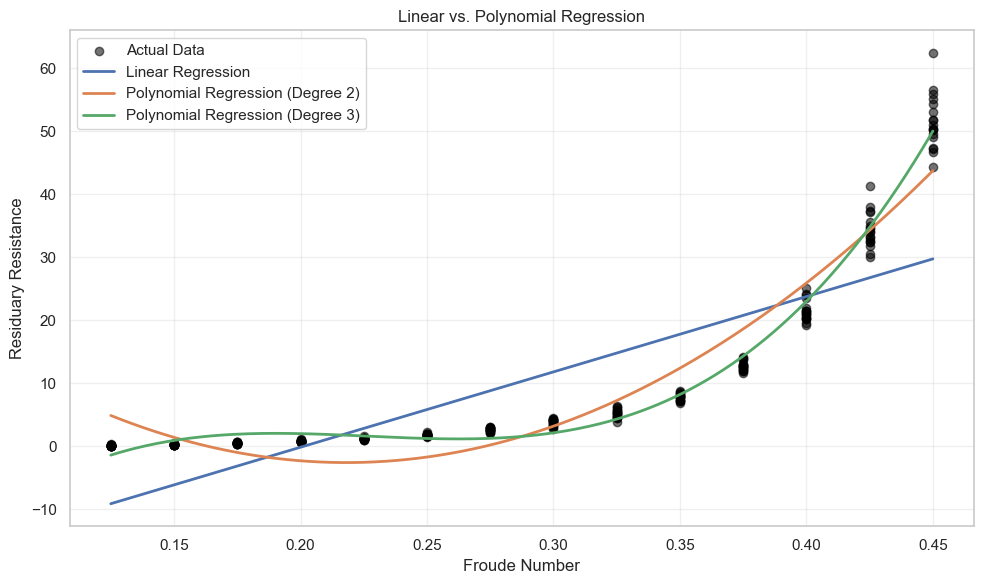

In [ ]:
# ============================================================
# SECTION 11: LINEAR VS POLYNOMIAL REGRESSION VISUALIZATION
# ============================================================

X_curve = df[["Froude_Number"]]
y_curve = df["Residuary_Resistance"]

# Use the same training and testing split for all three models
X_curve_train, X_curve_test, y_curve_train, y_curve_test = (
    train_test_split(
        X_curve,
        y_curve,
        test_size=0.20,
        random_state=42
    )
)

# Model 1: Linear Regression
curve_linear_model = LinearRegression()

curve_linear_model.fit(
    X_curve_train,
    y_curve_train
)

# Model 2: Polynomial Regression Degree 2
curve_poly2_model = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(degree=2, include_bias=False)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

curve_poly2_model.fit(
    X_curve_train,
    y_curve_train
)

# Model 3: Polynomial Regression Degree 3
curve_poly3_model = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(degree=3, include_bias=False)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

curve_poly3_model.fit(
    X_curve_train,
    y_curve_train
)

# Generate sorted values for smooth curves
X_curve_plot = pd.DataFrame({
    "Froude_Number": np.linspace(
        X_curve["Froude_Number"].min(),
        X_curve["Froude_Number"].max(),
        300
    )
})

# Predict values for each model
linear_curve_predictions = curve_linear_model.predict(
    X_curve_plot
)

poly2_curve_predictions = curve_poly2_model.predict(
    X_curve_plot
)

poly3_curve_predictions = curve_poly3_model.predict(
    X_curve_plot
)

# Plot the actual data and fitted models
plt.figure(figsize=(11, 7))

plt.scatter(
    X_curve["Froude_Number"],
    y_curve,
    alpha=0.6,
    label="Actual Data"
)

plt.plot(
    X_curve_plot["Froude_Number"],
    linear_curve_predictions,
    label="Linear Regression",
    linewidth=2
)

plt.plot(
    X_curve_plot["Froude_Number"],
    poly2_curve_predictions,
    label="Polynomial Regression (Degree 2)",
    linewidth=2
)

plt.plot(
    X_curve_plot["Froude_Number"],
    poly3_curve_predictions,
    label="Polynomial Regression (Degree 3)",
    linewidth=2
)

plt.title(
    "Linear vs Polynomial Regression: Froude Number and Resistance"
)

plt.xlabel("Froude Number")
plt.ylabel("Residuary Resistance")

plt.legend()
plt.tight_layout()
plt.show()

Cell 13 — Split Data into Training and Testing Sets

In [16]:
# ============================================================
# SECTION 12: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTRAINING AND TESTING DATA")

print("Original dataset size:", X.shape)
print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

print("\nTraining target size:", y_train.shape)
print("Testing target size:", y_test.shape)


TRAINING AND TESTING DATA
Original dataset size: (252, 6)
Training data size: (201, 6)
Testing data size: (51, 6)

Training target size: (201,)
Testing target size: (51,)


Cell 14 — Train Linear Regression

In [17]:
# ============================================================
# SECTION 13: MODEL 1 - LINEAR REGRESSION
# ============================================================

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


Cell 15 — Train Polynomial Regression (Degree 2)

In [18]:
# ============================================================
# SECTION 14: MODEL 2 - POLYNOMIAL REGRESSION DEGREE 2
# ============================================================

polynomial_model_2 = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(
            degree=2,
            include_bias=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

polynomial_model_2.fit(
    X_train,
    y_train
)

print("Polynomial Regression Degree 2 trained successfully.")

Polynomial Regression Degree 2 trained successfully.


Cell 16 — Train Polynomial Regression (Degree 3)

In [19]:
# ============================================================
# SECTION 15: MODEL 3 - POLYNOMIAL REGRESSION DEGREE 3
# ============================================================

polynomial_model_3 = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(
            degree=3,
            include_bias=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

polynomial_model_3.fit(
    X_train,
    y_train
)

print("Polynomial Regression Degree 3 trained successfully.")

print("\nALL THREE MODELS HAVE BEEN TRAINED SUCCESSFULLY.")

Polynomial Regression Degree 3 trained successfully.

ALL THREE MODELS HAVE BEEN TRAINED SUCCESSFULLY.


Cell 17 — Make Predictions

In [20]:
# ============================================================
# SECTION 16: MAKE PREDICTIONS
# ============================================================

models = {
    "Linear Regression": linear_model,
    "Polynomial Regression (Degree 2)": polynomial_model_2,
    "Polynomial Regression (Degree 3)": polynomial_model_3
}

train_predictions = {}
test_predictions = {}

for model_name, model in models.items():

    train_predictions[model_name] = model.predict(X_train)

    test_predictions[model_name] = model.predict(X_test)

print("Predictions generated for all models.")

Predictions generated for all models.


Cell 18 — Evaluate Model Performance

In [21]:
# ============================================================
# SECTION 17: MODEL PERFORMANCE COMPARISON
# ============================================================

results = []

for model_name in models:

    train_pred = train_predictions[model_name]
    test_pred = test_predictions[model_name]

    train_mse = mean_squared_error(
        y_train,
        train_pred
    )

    test_mse = mean_squared_error(
        y_test,
        test_pred
    )

    train_r2 = r2_score(
        y_train,
        train_pred
    )

    test_r2 = r2_score(
        y_test,
        test_pred
    )

    results.append({
        "Model": model_name,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train R2": train_r2,
        "Test R2": test_r2
    })

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")

print(
    results_df.to_string(
        index=False,
        formatters={
            "Train MSE": "{:.4f}".format,
            "Test MSE": "{:.4f}".format,
            "Train R2": "{:.4f}".format,
            "Test R2": "{:.4f}".format
        }
    )
)


MODEL PERFORMANCE COMPARISON
                           Model Train MSE Test MSE Train R2 Test R2
               Linear Regression   83.2553  53.4783   0.6476  0.6781
Polynomial Regression (Degree 2)   16.0996  17.5482   0.9319  0.8944
Polynomial Regression (Degree 3)    1.7417   2.4295   0.9926  0.9854


Cell 19 — Compare Test MSE

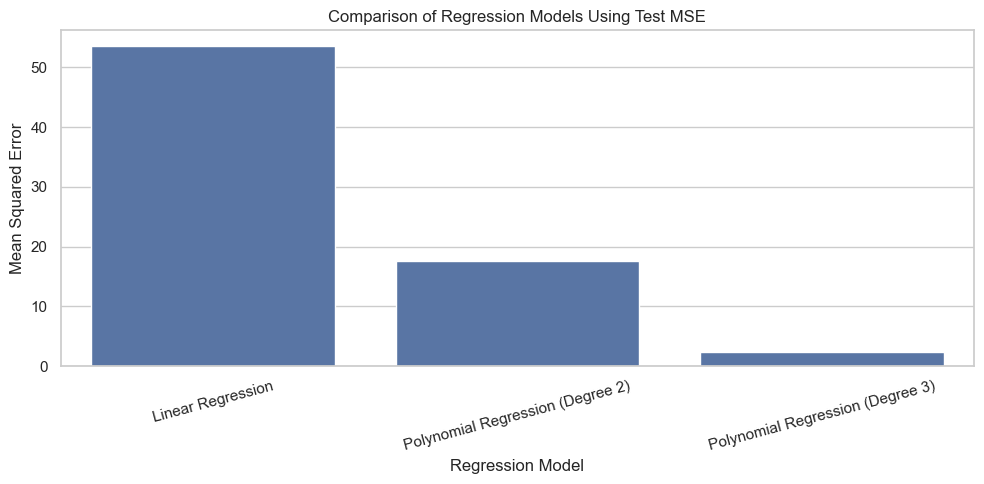

In [22]:
# ============================================================
# SECTION 18: VISUALIZE TEST MSE
# ============================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test MSE"
)

plt.title("Comparison of Regression Models Using Test MSE")
plt.xlabel("Regression Model")
plt.ylabel("Mean Squared Error")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Cell 20 — Compare Test R²

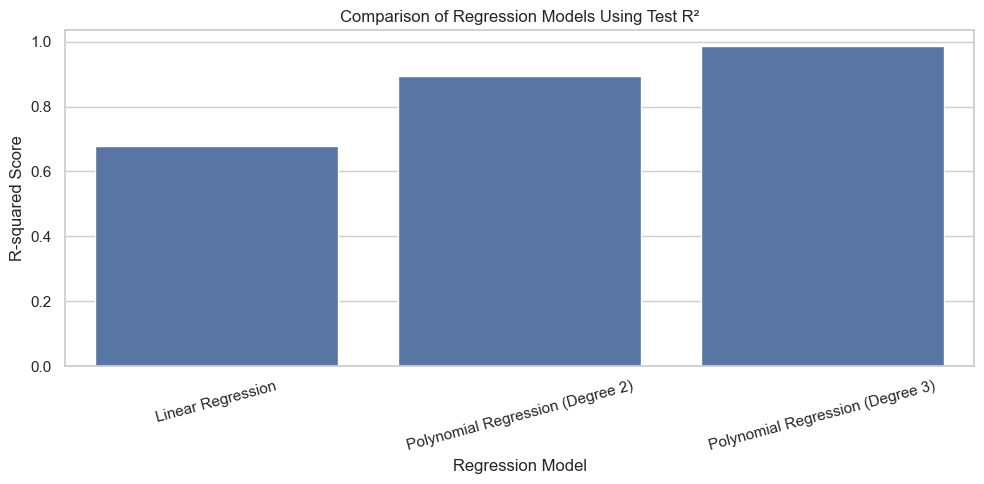

In [23]:
# ============================================================
# SECTION 19: VISUALIZE TEST R-SQUARED
# ============================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test R2"
)

plt.title("Comparison of Regression Models Using Test R²")
plt.xlabel("Regression Model")
plt.ylabel("R-squared Score")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Cell 21 — Actual vs Predicted Values

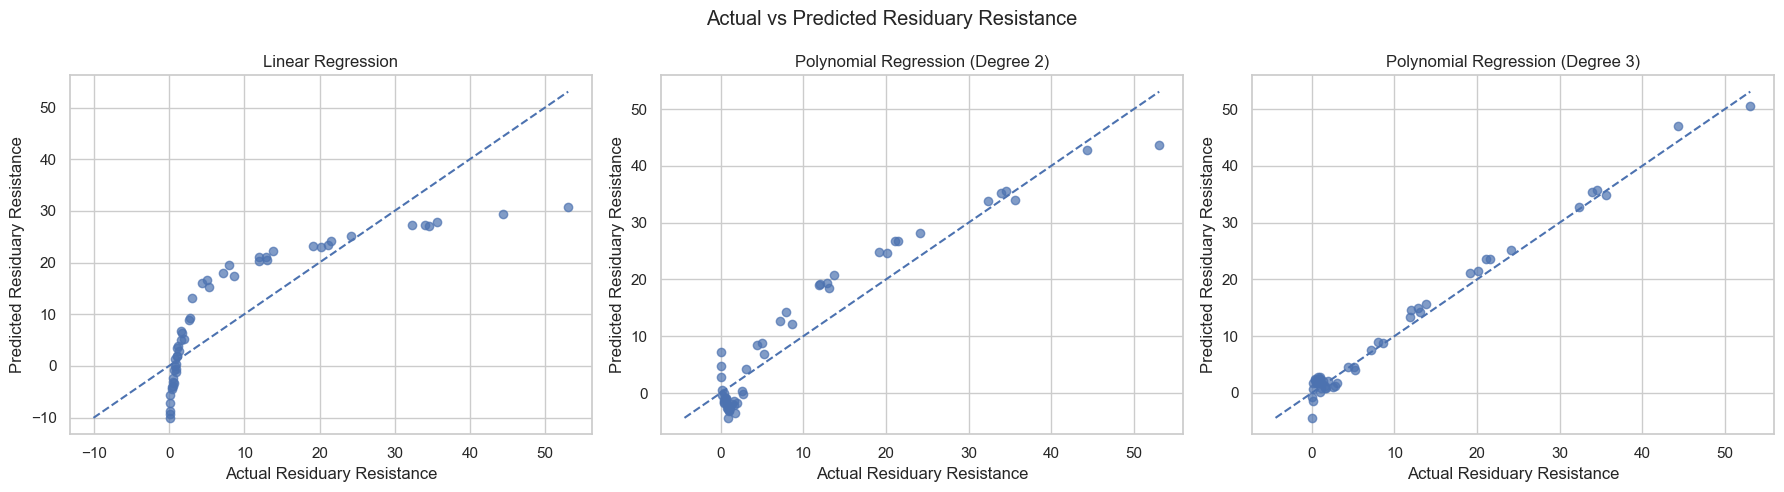

In [24]:
# ============================================================
# SECTION 20: ACTUAL VS PREDICTED VALUES
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, predictions) in zip(
    axes,
    test_predictions.items()
):

    ax.scatter(
        y_test,
        predictions,
        alpha=0.7
    )

    min_value = min(
        y_test.min(),
        predictions.min()
    )

    max_value = max(
        y_test.max(),
        predictions.max()
    )

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual Residuary Resistance")
    ax.set_ylabel("Predicted Residuary Resistance")

plt.suptitle("Actual vs Predicted Residuary Resistance")

plt.tight_layout()
plt.show()

Cell 22 — Residual Analysis

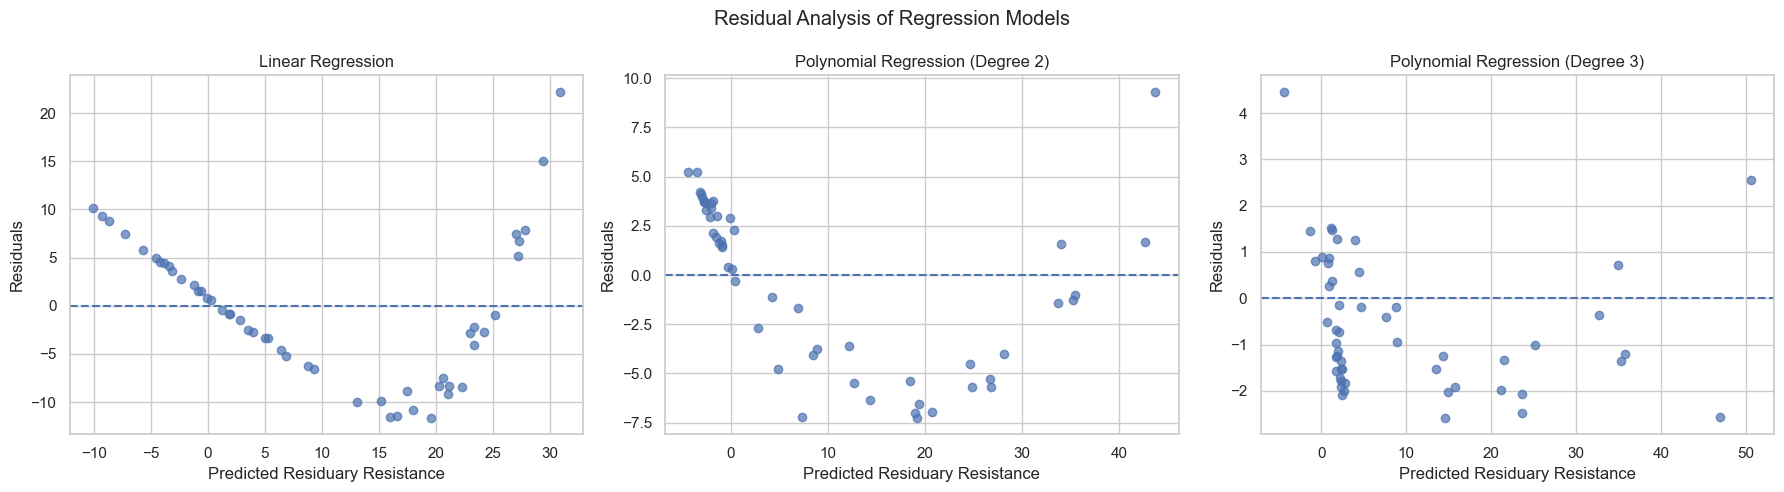

In [25]:
# ============================================================
# SECTION 21: RESIDUAL ANALYSIS
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, predictions) in zip(
    axes,
    test_predictions.items()
):

    residuals = y_test.to_numpy() - predictions

    ax.scatter(
        predictions,
        residuals,
        alpha=0.7
    )

    ax.axhline(
        y=0,
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Residuary Resistance")
    ax.set_ylabel("Residuals")

plt.suptitle("Residual Analysis of Regression Models")

plt.tight_layout()
plt.show()

Cell 23 — Check for Overfitting and Underfitting

In [26]:
# ============================================================
# SECTION 22: OVERFITTING AND UNDERFITTING CHECK
# ============================================================

print("\nOVERFITTING AND UNDERFITTING CHECK")

for _, row in results_df.iterrows():

    model_name = row["Model"]

    train_r2 = row["Train R2"]
    test_r2 = row["Test R2"]

    difference = train_r2 - test_r2

    print("\nModel:", model_name)
    print("Training R²:", round(train_r2, 4))
    print("Testing R²:", round(test_r2, 4))
    print("Train-Test R² Difference:", round(difference, 4))

    if train_r2 < 0.50 and test_r2 < 0.50:

        print(
            "Interpretation: Both scores are relatively low. "
            "The model may be underfitting."
        )

    elif difference > 0.10:

        print(
            "Interpretation: The model may be overfitting "
            "because training performance is noticeably better."
        )

    else:

        print(
            "Interpretation: No large train-test R² gap "
            "was detected using this simple check."
        )


OVERFITTING AND UNDERFITTING CHECK

Model: Linear Regression
Training R²: 0.6476
Testing R²: 0.6781
Train-Test R² Difference: -0.0305
Interpretation: No large train-test R² gap was detected using this simple check.

Model: Polynomial Regression (Degree 2)
Training R²: 0.9319
Testing R²: 0.8944
Train-Test R² Difference: 0.0375
Interpretation: No large train-test R² gap was detected using this simple check.

Model: Polynomial Regression (Degree 3)
Training R²: 0.9926
Testing R²: 0.9854
Train-Test R² Difference: 0.0073
Interpretation: No large train-test R² gap was detected using this simple check.


Cell 24 — Select the Best Model

In [27]:
# ============================================================
# SECTION 23: SELECT THE BEST MODEL
# ============================================================

best_model_row = results_df.loc[
    results_df["Test MSE"].idxmin()
]

best_model_name = best_model_row["Model"]

best_model = models[best_model_name]

print("\nBEST MODEL BASED ON TEST MSE")

print("Model:", best_model_name)
print("Test MSE:", round(best_model_row["Test MSE"], 4))
print("Test R²:", round(best_model_row["Test R2"], 4))


BEST MODEL BASED ON TEST MSE
Model: Polynomial Regression (Degree 3)
Test MSE: 2.4295
Test R²: 0.9854


Cell 25 — Display Sample Predictions

In [28]:
# ============================================================
# SECTION 24: SAMPLE ACTUAL VS PREDICTED VALUES
# ============================================================

best_predictions = test_predictions[best_model_name]

comparison_df = pd.DataFrame({
    "Actual_Resistance": y_test.to_numpy(),
    "Predicted_Resistance": best_predictions
})

comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Resistance"]
    - comparison_df["Predicted_Resistance"]
)

print("\nSAMPLE ACTUAL VS PREDICTED VALUES")

print(
    comparison_df.head(10).round(4).to_string(index=False)
)


SAMPLE ACTUAL VS PREDICTED VALUES
 Actual_Resistance  Predicted_Resistance  Absolute_Error
             24.14               25.1407          1.0007
              2.61                1.0872          1.5228
             44.38               46.9510          2.5710
              1.15                0.8768          0.2732
              0.86                1.9924          1.1324
              0.17                0.6837          0.5137
              0.63                1.8770          1.2470
             20.14               21.4750          1.3350
              7.16                7.5646          0.4046
              0.56                2.3369          1.7769


Cell 26 — Predict Resistance for a New Yacht

In [29]:
# ============================================================
# SECTION 25: PREDICT RESIDUARY RESISTANCE FOR A NEW YACHT
# ============================================================

new_yacht = pd.DataFrame([{
    feature: X[feature].median()
    for feature in feature_columns
}])

print("\nNEW YACHT INPUT FEATURES")
print(new_yacht.to_string(index=False))

predicted_resistance = best_model.predict(new_yacht)[0]

print("\nNEW YACHT PREDICTION")
print(
    "Predicted Residuary Resistance:",
    round(predicted_resistance, 4)
)


NEW YACHT INPUT FEATURES
 Center_of_Buoyancy  Prismatic_Coefficient  Length_Displacement_Ratio  Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number
               -2.3                  0.565                       4.78               3.955              3.155         0.2875

NEW YACHT PREDICTION
Predicted Residuary Resistance: 1.2852


Cell 27 — Final Summary

In [30]:
# ============================================================
# SECTION 26: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL SUMMARY")
print("=" * 65)

print("Dataset: Yacht Hydrodynamics")
print("Total observations:", len(df))
print("Number of input features:", len(feature_columns))
print("Target variable: Residuary_Resistance")
print("Models evaluated:", len(results_df))

print("\nMODELS:")
for model_name in models:
    print("-", model_name)

print("\nBEST MODEL BASED ON TEST MSE:", best_model_name)

print(
    "Best model Test MSE:",
    round(best_model_row["Test MSE"], 4)
)

print(
    "Best model Test R²:",
    round(best_model_row["Test R2"], 4)
)

print("\nANALYSIS COMPLETED SUCCESSFULLY.")


FINAL SUMMARY
Dataset: Yacht Hydrodynamics
Total observations: 252
Number of input features: 6
Target variable: Residuary_Resistance
Models evaluated: 3

MODELS:
- Linear Regression
- Polynomial Regression (Degree 2)
- Polynomial Regression (Degree 3)

BEST MODEL BASED ON TEST MSE: Polynomial Regression (Degree 3)
Best model Test MSE: 2.4295
Best model Test R²: 0.9854

ANALYSIS COMPLETED SUCCESSFULLY.
